# Fitting commuting generators to the grid cells (Fig. 4, App. K)

Fits the exponential map to the rate maps of 102 grid cells of one module of one rat (Gardner
et al. 2022) and writes `data/gc_fit_commuting.npz`, which `fitting_figures` and
`fitted_similarity_structure` read.

The generators keep the form of Sec. 2.3,

$$G_x = R^\top \Sigma_x R, \qquad G_y = R^\top \Sigma_y R.$$

$R = e^{B - B^\top}$ is orthogonal for any matrix $B$. $\Sigma_x$ and $\Sigma_y$ are block
diagonal with $2 \times 2$ skew-symmetric blocks, one wavevector $(\lambda_{i,x}, \lambda_{i,y})$
per block (App. C). The learnable parameters are $B$ and the wavevectors, so the generators are
skew-symmetric and commute for every parameter value. The loss is the one-step prediction error,

$$L = \big\langle \|p(r + \delta r) - e^{\delta x G_x + \delta y G_y}p(r)\|^2 \big\rangle.$$

A batch has 32 pairs. The start bins are drawn uniformly over the map and the steps are up to
two bins along each axis, reflected at the boundary. Adam runs for 20 000 iterations at
seed 0 (App. K).

In the eigenbasis of the generators, $\alpha = R\,p$, a step rotates each pair of coordinates
by the angle $\delta x\,\lambda_{i,x} + \delta y\,\lambda_{i,y}$ (App. C). The fit transports
with these rotations instead of the matrix exponential, which makes a training step cheap.

Two evaluations follow (App. K). The reconstruction regenerates the whole arena from the
recorded population vector at its center and compares the result with the data unit by unit.
The extrapolation refits the model to the central three quarters of the arena side and
predicts the part no training step touched. `fit_place_cells` evaluates the CA1 fit the same
way.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from expmap.fitting import CommutingGeneratorFit

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
DATA = REPO_ROOT / "data" / "gc_ratmaps.npy"
OUTPUT = REPO_ROOT / "data" / "gc_fit_commuting.npz"
sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))
from galleries import gallery  # noqa: E402

N_STEPS = 20000
BATCH_SIZE = 32
MAX_STEP = 2  # largest pixel step per axis
LR = 1e-3  # for R
WAVEVECTOR_LR = 1e-2
ARENA_SIZE = 1.0  # experimental maps span [-1, 1], so one pixel is 2/32
SEED = 0

# The extrapolation fit sees the central square of this fraction of the arena side.
FITTED_FRACTION = 0.75
CHANCE_DRAWS = 200

In [2]:
# Stored as (n_units, bins_x, bins_y). The fit wants position first, so that a bin index
# returns a population vector.
experimental = np.load(DATA).astype("float32")
ratemaps = torch.tensor(np.transpose(experimental, (1, 2, 0)))

N_UNITS, N_BINS = experimental.shape[0], experimental.shape[1]
print(f"{N_UNITS} units, {N_BINS} x {N_BINS} bins, rate range {experimental.min():.4f}..{experimental.max():.4f}")

102 units, 32 x 32 bins, rate range 0.0001..0.1999


## Fit

loss 1.512e-04 -> 4.811e-05


Text(0, 0.5, 'loss')

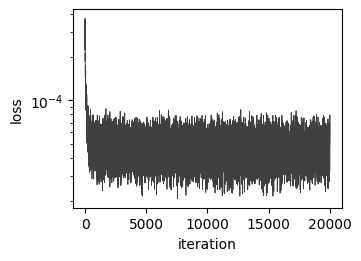

In [3]:
fit = CommutingGeneratorFit(n_units=N_UNITS, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
loss_history = fit.fit(ratemaps, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=ARENA_SIZE, progress=False)
print(f"loss {np.mean(loss_history[:100]):.3e} -> {np.mean(loss_history[-100:]):.3e}")

fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
ax.semilogy(loss_history, "k", linewidth=0.6, alpha=0.75)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")

## Reconstruction

The recorded population vector at the arena center is transported to every bin,
$p(x, y) = e^{x G_x + y G_y}\,p(0, 0)$, and the generated map of each unit is compared with its
recorded map through the Pearson correlation over bins. The correlation ignores amplitude. The
data are not equinorm and an orthogonal model is, so the generated maps differ from the data in
amplitude wherever the norm of the recorded population vector varies.


correlation, model vs data: median 0.76, 10th to 90th percentile 0.59 to 0.83


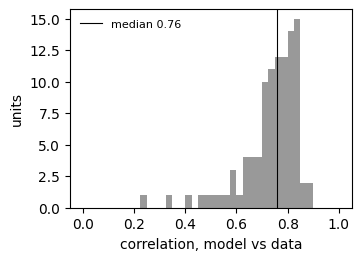

In [4]:
centre = ratemaps[N_BINS // 2, N_BINS // 2]
generated = fit.generate(centre, n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()
correlation = np.array([np.corrcoef(g.ravel(), e.ravel())[0, 1] for g, e in zip(generated, experimental)])
print(f"correlation, model vs data: median {np.median(correlation):.2f}, 10th to 90th percentile {np.percentile(correlation, 10):.2f} to {np.percentile(correlation, 90):.2f}")

fig, ax = plt.subplots(figsize=(3.5, 2.5), layout="constrained")
ax.hist(correlation, bins=np.linspace(0, 1, 41), color="0.6")
ax.axvline(np.median(correlation), color="k", linewidth=0.8, label=f"median {np.median(correlation):.2f}")
ax.set_xlabel("correlation, model vs data")
ax.set_ylabel("units")
ax.legend(frameon=False, fontsize=8, loc="upper left")

### Data and model side by side

Units sorted by correlation, best to worst, evenly sampled. Rows alternate data and model, and
each pair shares the unit's own scale.


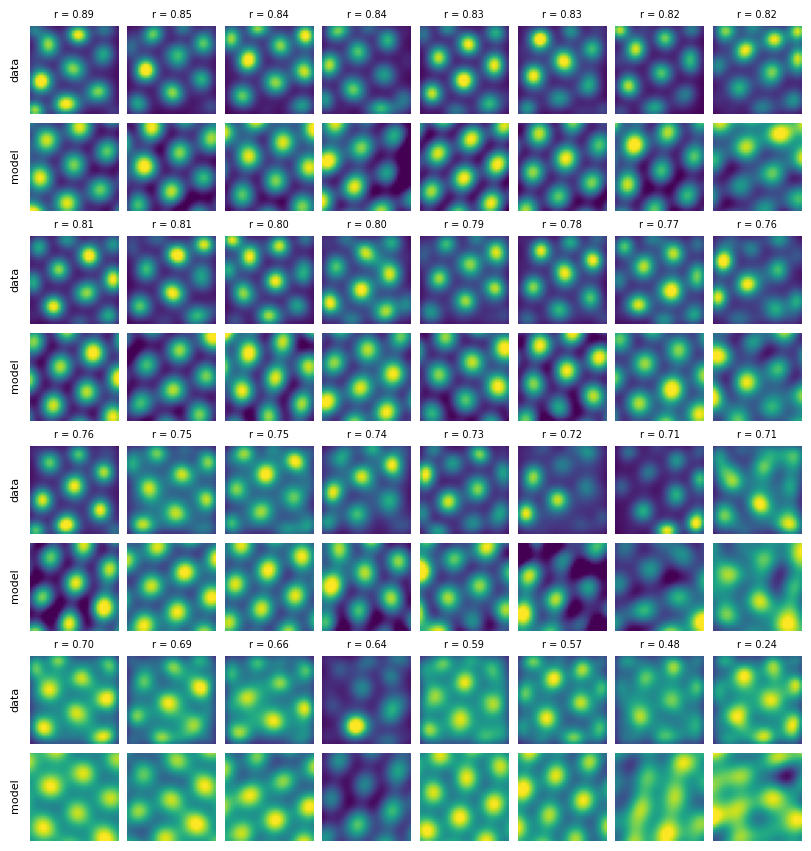

In [5]:
fig = gallery(experimental, generated, correlation)

## Extrapolation beyond the fitted square

The model is fitted anew to the central square spanning `FITTED_FRACTION` of the arena side,
and the whole arena is generated from its center at the same bin size. The outer bins are then
compared with data no training step touched. Two chance levels, each the mean over
`CHANCE_DRAWS` draws of the median correlation: the untrained part of each recorded map with its bins
shuffled, and each unit's prediction against the data of a random other unit.


fitted square: bins 4 to 27 of 32, 44% of the arena untrained
correlation inside the fitted square: median 0.92
correlation on the untrained part: median 0.71, 10th to 90th percentile 0.51 to 0.80
chance on the untrained part: bins shuffled -0.00, units shuffled -0.03


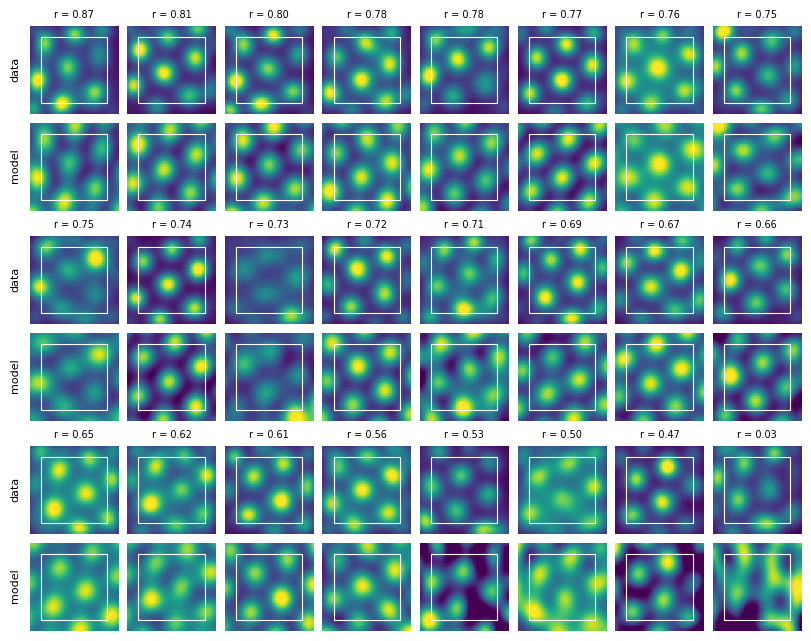

In [6]:
lo = round(N_BINS * (1 - FITTED_FRACTION) / 2)
hi = N_BINS - lo
inner = np.zeros((N_BINS, N_BINS), bool)
inner[lo:hi, lo:hi] = True
crop = ratemaps[lo:hi, lo:hi]

# The crop spans [-FITTED_FRACTION, FITTED_FRACTION] of the arena, so its bins are the arena's bins.
crop_fit = CommutingGeneratorFit(n_units=N_UNITS, lr=LR, wavevector_lr=WAVEVECTOR_LR, seed=SEED)
crop_loss = crop_fit.fit(crop, n_steps=N_STEPS, batch_size=BATCH_SIZE, max_step=MAX_STEP, arena_size=FITTED_FRACTION * ARENA_SIZE, progress=False)
extrapolated = crop_fit.generate(crop[(hi - lo) // 2, (hi - lo) // 2], n_bins=N_BINS, extent=1.0, arena_size=ARENA_SIZE).numpy()


def correlation_over(model, data, where):
    return np.array([np.corrcoef(g[where], e[where])[0, 1] for g, e in zip(model, data)])


inner_corr = correlation_over(extrapolated, experimental, inner)
outer_corr = correlation_over(extrapolated, experimental, ~inner)
rng = np.random.default_rng(SEED)
unit_chance = np.mean([np.median(correlation_over(extrapolated[rng.permutation(N_UNITS)], experimental, ~inner)) for _ in range(CHANCE_DRAWS)])
bin_chance = np.mean(
    [np.median([np.corrcoef(g[~inner], rng.permutation(e[~inner]))[0, 1] for g, e in zip(extrapolated, experimental)]) for _ in range(CHANCE_DRAWS)]
)

print(f"fitted square: bins {lo} to {hi - 1} of {N_BINS}, {1 - FITTED_FRACTION**2:.0%} of the arena untrained")
print(f"correlation inside the fitted square: median {np.median(inner_corr):.2f}")
print(f"correlation on the untrained part: median {np.median(outer_corr):.2f}, 10th to 90th percentile {np.percentile(outer_corr, 10):.2f} to {np.percentile(outer_corr, 90):.2f}")
print(f"chance on the untrained part: bins shuffled {bin_chance:.2f}, units shuffled {unit_chance:.2f}")

fig = gallery(experimental, extrapolated, outer_corr, box=(lo, hi), n_show=24)

## Save

In [7]:
np.savez_compressed(
    OUTPUT,
    Gx=fit.Gx.detach().numpy(),
    Gy=fit.Gy.detach().numpy(),
    R=fit.R.detach().numpy(),
    wavevectors=fit.wavevectors.detach().numpy(),
    loss_history=np.array(loss_history),
    experimental=experimental,
    generated=generated,
    correlation=correlation,
    seed=SEED,
    n_steps=N_STEPS,
    fitted_fraction=FITTED_FRACTION,
    inner=inner,
    extrapolated=extrapolated,
    crop_Gx=crop_fit.Gx.detach().numpy(),
    crop_Gy=crop_fit.Gy.detach().numpy(),
    crop_loss_history=np.array(crop_loss),
    outer_correlation=outer_corr,
    outer_correlation_chance=unit_chance,
)
print(f"saved {OUTPUT.name}")

saved gc_fit_commuting.npz
